In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Project environment is ready!")

Project environment is ready!


In [6]:
file_path = "../PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(file_path, nrows=10)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: '../PS_20174392719_1491204439457_log.csv'

In [1]:
import os
import sys

print("Current Working Directory:")
print(os.getcwd())

print("\nPython Interpreter:")
print(sys.executable)

Current Working Directory:
c:\ML_Projects\Mobile_Wallet_Fraud_Detection

Python Interpreter:
c:\ML_Projects\Mobile_Wallet_Fraud_Detection\.venv\Scripts\python.exe


In [3]:
import sys

print(sys.executable)

c:\ML_Projects\Mobile_Wallet_Fraud_Detection\.venv\Scripts\python.exe


In [5]:
import pandas as pd

file_path = "PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(file_path, nrows=10)

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [7]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [9]:
df.shape

(10, 11)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            10 non-null     int64  
 1   type            10 non-null     str    
 2   amount          10 non-null     float64
 3   nameOrig        10 non-null     str    
 4   oldbalanceOrg   10 non-null     float64
 5   newbalanceOrig  10 non-null     float64
 6   nameDest        10 non-null     str    
 7   oldbalanceDest  10 non-null     float64
 8   newbalanceDest  10 non-null     float64
 9   isFraud         10 non-null     int64  
 10  isFlaggedFraud  10 non-null     int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 1.3 KB


In [13]:
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

Dataset Shape: (6362620, 11)


In [15]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [17]:
df['isFraud'].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

In [19]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [21]:
fraud_by_type = pd.crosstab(
    df['type'],
    df['isFraud'],
    normalize='index'
) * 100

fraud_by_type

isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,99.816045,0.183955
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,99.231201,0.768799


Fraudulent transactions in the PaySim dataset are concentrated in TRANSFER and CASH_OUT transaction types, with TRANSFER showing the highest fraud rate.

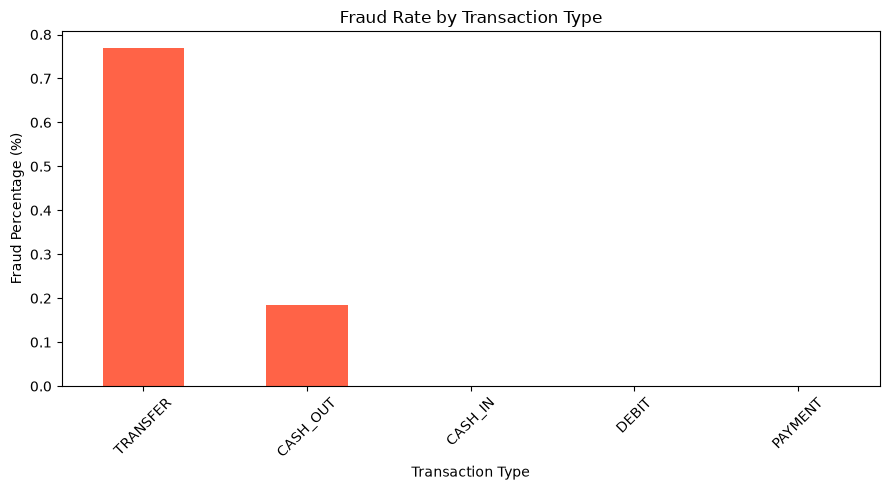

In [26]:
fraud_by_type[1].sort_values(ascending=False).plot(
    kind='bar',
    figsize=(9, 5),
    color='tomato'
)

plt.title('Fraud Rate by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Fraud Percentage (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
import matplotlib.pyplot as plt

In [28]:
df.groupby('isFraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


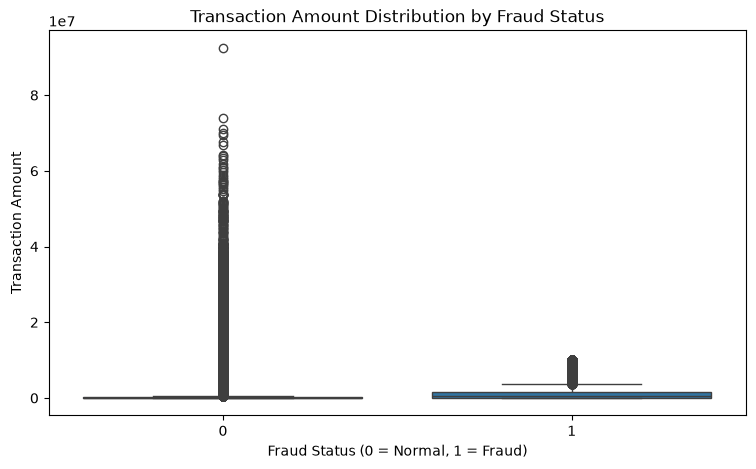

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='isFraud',
    y='amount'
)

plt.title('Transaction Amount Distribution by Fraud Status')
plt.xlabel('Fraud Status (0 = Normal, 1 = Fraud)')
plt.ylabel('Transaction Amount')

plt.show()

In [30]:
fraud_counts = pd.crosstab(
    df['type'],
    df['isFraud']
)

fraud_counts

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [31]:
fraud_percentage = (
    fraud_counts[1] / fraud_counts.sum(axis=1)
) * 100

fraud_percentage.sort_values(ascending=False)

type
TRANSFER    0.768799
CASH_OUT    0.183955
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
dtype: float64

Fraudulent transactions in the PaySim dataset are concentrated in TRANSFER and CASH_OUT transaction types. Although CASH_OUT has the highest number of fraudulent transactions (4,116), TRANSFER has the highest fraud rate (0.7688%). This suggests that transaction type may be an important feature for fraud detection.

In [32]:
fraud_by_step = df.groupby('step')['isFraud'].sum()

fraud_by_step.describe()

count    743.000000
mean      11.053836
std        4.998631
min        0.000000
25%        8.000000
50%       10.000000
75%       14.000000
max       40.000000
Name: isFraud, dtype: float64

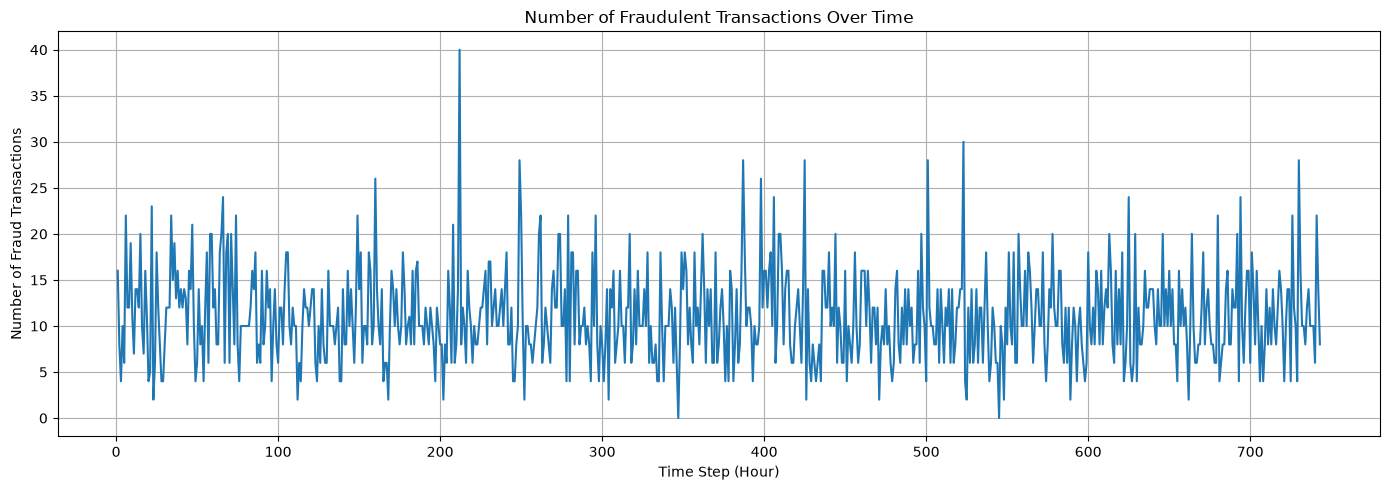

In [33]:
plt.figure(figsize=(14, 5))

fraud_by_step.plot()

plt.title('Number of Fraudulent Transactions Over Time')
plt.xlabel('Time Step (Hour)')
plt.ylabel('Number of Fraud Transactions')

plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
fraud_time_analysis = df.groupby('step')['isFraud'].agg(
    total_transactions='count',
    fraud_transactions='sum'
)

fraud_time_analysis['fraud_rate'] = (
    fraud_time_analysis['fraud_transactions'] /
    fraud_time_analysis['total_transactions']
) * 100

fraud_time_analysis.head(10)

,total_transactions,fraud_transactions,fraud_rate
step,,,
1,2708,16,0.590842
2,1014,8,0.788955
3,552,4,0.724638
4,565,10,1.769912
5,665,6,0.902256
6,1660,22,1.325301
7,6837,12,0.175516
8,21097,12,0.056880
9,37628,19,0.050494


In [36]:
fraud_time_analysis.sort_values(
    by='fraud_rate',
    ascending=False
).head(10)

,total_transactions,fraud_transactions,fraud_rate
step,,,
727,12,12,100.0
743,8,8,100.0
742,14,14,100.0
410,20,20,100.0
411,16,16,100.0
412,8,8,100.0
414,16,16,100.0
415,16,16,100.0
417,6,6,100.0


In [38]:
reliable_time_analysis = fraud_time_analysis[
    fraud_time_analysis['total_transactions'] >= 100
]

reliable_time_analysis.sort_values(
    by='fraud_rate',
    ascending=False
).head(10)

,total_transactions,fraud_transactions,fraud_rate
step,,,
578,269,20,7.434944
195,141,10,7.092199
436,248,16,6.451613
716,140,8,5.714286
531,250,14,5.600000
672,153,8,5.228758
509,288,14,4.861111
413,289,14,4.844291
555,144,6,4.166667


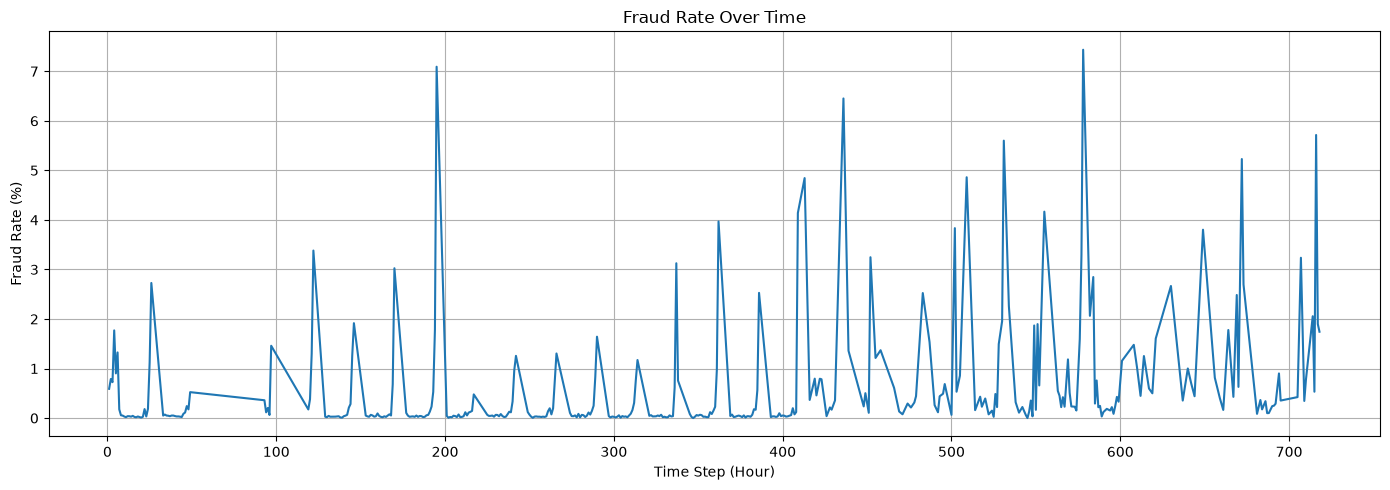

In [39]:
plt.figure(figsize=(14, 5))

plt.plot(
    reliable_time_analysis.index,
    reliable_time_analysis['fraud_rate']
)

plt.title('Fraud Rate Over Time')
plt.xlabel('Time Step (Hour)')
plt.ylabel('Fraud Rate (%)')

plt.grid(True)
plt.tight_layout()
plt.show()

## Machine learning 

In [40]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)

Missing Values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Data Types:
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object


In [42]:
# Select input features
X = df.drop(
    columns=['nameOrig', 'nameDest', 'isFraud', 'isFlaggedFraud']
)

# Select target variable
y = df['isFraud']

# Check the results
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Features Shape: (6362620, 7)
Target Shape: (6362620,)

Feature Columns:
['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']


In [43]:
print(X['type'].value_counts())

print("\nUnique Transaction Types:")
print(X['type'].unique())

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Unique Transaction Types:
<ArrowStringArray>
['PAYMENT', 'TRANSFER', 'CASH_OUT', 'DEBIT', 'CASH_IN']
Length: 5, dtype: str


In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (5090096, 7)
Testing Features: (1272524, 7)

Training Target:
isFraud
0    99.870926
1     0.129074
Name: proportion, dtype: float64

Testing Target:
isFraud
0    99.870887
1     0.129113
Name: proportion, dtype: float64


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = ['type']

# Create preprocessing pipelines
numerical_transformer = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)
print("Preprocessor created successfully!")

Numerical Features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Categorical Features: ['type']
Preprocessor created successfully!


In [46]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

baseline_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', DummyClassifier(strategy='most_frequent'))
    ]
)

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_baseline))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

Accuracy: 0.9987088652159016

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.00      0.00      0.00      1643

    accuracy                           1.00   1272524
   macro avg       0.50      0.50      0.50   1272524
weighted avg       1.00      1.00      1.00   1272524


Confusion Matrix:
[[1270881       0]
 [   1643       0]]


In [47]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression Results:")
print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

Logistic Regression Results:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.95      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524

Confusion Matrix:
[[1206133   64748]
 [     66    1577]]


In [48]:
from sklearn.metrics import average_precision_score

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

pr_auc = average_precision_score(
    y_test,
    y_prob_logistic
)

print("Logistic Regression PR-AUC:", pr_auc)

Logistic Regression PR-AUC: 0.581741459643448


In [49]:
from sklearn.model_selection import train_test_split

X_rf, _, y_rf, _ = train_test_split(
    X_train,
    y_train,
    train_size=500000,
    random_state=42,
    stratify=y_train
)

print("Random Forest Training Shape:", X_rf.shape)
print("Fraud Cases in Sample:", y_rf.sum())

Random Forest Training Shape: (500000, 7)
Fraud Cases in Sample: 645


In [50]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=5,
            class_weight='balanced_subsample',
            n_jobs=-1,
            random_state=42
        ))
    ]
)

rf_model.fit(X_rf, y_rf)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['step','type','amount',...,'newbalanceOrig','oldbalanceDest', 'newbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

In [51]:
from sklearn.metrics import average_precision_score

y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Results:")

print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print(
    "Random Forest PR-AUC:",
    average_precision_score(y_test, y_prob_rf)
)

Random Forest Results:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00   1270881
           1       0.19      0.90      0.31      1643

    accuracy                           0.99   1272524
   macro avg       0.59      0.95      0.65   1272524
weighted avg       1.00      0.99      1.00   1272524

Confusion Matrix:
[[1264428    6453]
 [    170    1473]]
Random Forest PR-AUC: 0.844183973167649


# Decision Tree

In [52]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=5,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

dt_model.fit(X_rf, y_rf)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

In [53]:
from sklearn.metrics import average_precision_score

print("Decision Tree Results:")

print(classification_report(
    y_test,
    y_pred_dt,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print(
    "Decision Tree PR-AUC:",
    average_precision_score(y_test, y_prob_dt)
)

Decision Tree Results:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00   1270881
           1       0.16      0.88      0.27      1643

    accuracy                           0.99   1272524
   macro avg       0.58      0.94      0.63   1272524
weighted avg       1.00      0.99      1.00   1272524

Confusion Matrix:
[[1263100    7781]
 [    191    1452]]
Decision Tree PR-AUC: 0.7854409060271705


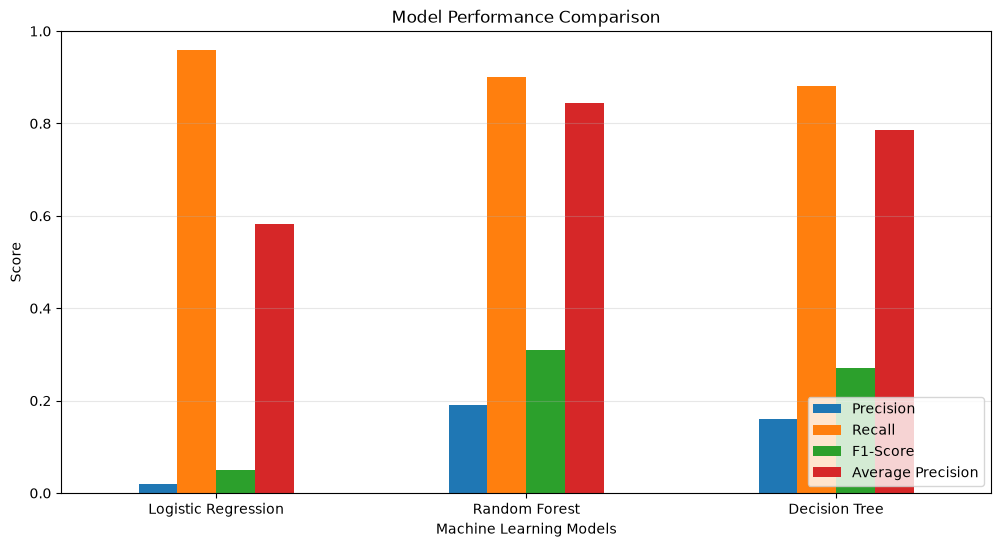

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Decision Tree'
    ],
    'Precision': [0.02, 0.19, 0.16],
    'Recall': [0.96, 0.90, 0.88],
    'F1-Score': [0.05, 0.31, 0.27],
    'Average Precision': [
        0.5817, 0.8442, 0.7854
    ]
})

model_comparison.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [55]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the Random Forest pipeline
rf_tuning_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Define the hyperparameters to test
param_distributions = {
    'classifier__n_estimators': [100, 150],
    'classifier__max_depth': [8, 12, 16],
    'classifier__min_samples_leaf': [5, 10],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

# Create RandomizedSearchCV
rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=4,
    cv=3,
    scoring='average_precision',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# Train and compare different configurations
rf_random_search.fit(X_rf, y_rf)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__class_weight': ['balanced', 'balanced_subsample'], 'classifier__max_depth': [8, 12, ...], 'classifier__min_samples_leaf': [5, 10], 'classifier__n_estimators': [100, 150]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",4
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing

In [56]:
print("Best Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation AP:")
print(rf_random_search.best_score_)

Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 16, 'classifier__class_weight': 'balanced'}

Best Cross-Validation AP:
0.847269445442756


In [57]:
from sklearn.model_selection import train_test_split

# Get training data that was not used in Random Forest tuning
remaining_indices = X_train.index.difference(X_rf.index)

X_remaining = X_train.loc[remaining_indices]
y_remaining = y_train.loc[remaining_indices]

# Create a validation set
X_unused, X_val, y_unused, y_val = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.20,
    random_state=42,
    stratify=y_remaining
)

print("Validation Shape:", X_val.shape)

print("\nValidation Fraud Distribution:")
print(y_val.value_counts())

print("\nValidation Fraud Percentage:")
print(y_val.value_counts(normalize=True) * 100)

Validation Shape: (918020, 7)

Validation Fraud Distribution:
isFraud
0    916835
1      1185
Name: count, dtype: int64

Validation Fraud Percentage:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


In [59]:
# Get the best tuned Random Forest model
best_rf_model = rf_random_search.best_estimator_

# Predict fraud probabilities on validation data
y_prob_val = best_rf_model.predict_proba(X_val)[:, 1]

print("Validation predictions completed!")

Validation predictions completed!


In [60]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Different threshold values to test
thresholds = [
    0.1, 0.2, 0.3, 0.4,
    0.5, 0.6, 0.7, 0.8, 0.9
]

results = []

for threshold in thresholds:

    # Convert probabilities into predictions
    y_pred_threshold = (
        y_prob_val >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    precision = precision_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'False Positives': fp,
        'False Negatives': fn,
        'True Positives': tp
    })

# Display results
threshold_results = pd.DataFrame(results)

print(threshold_results.round(4))

   Threshold  Precision  Recall  F1-Score  False Positives  False Negatives  \
0        0.1     0.0600  0.9865    0.1131            18314               16   
1        0.2     0.1100  0.9603    0.1973             9211               47   
2        0.3     0.1748  0.9359    0.2945             5237               76   
3        0.4     0.3056  0.9165    0.4583             2468               99   
4        0.5     0.4359  0.8810    0.5832             1351              141   
5        0.6     0.5773  0.8414    0.6848              730              188   
6        0.7     0.7700  0.8051    0.7871              285              231   
7        0.8     0.9084  0.7612    0.8283               91              283   
8        0.9     0.9834  0.7004    0.8181               14              355   

   True Positives  
0            1169  
1            1138  
2            1109  
3            1086  
4            1044  
5             997  
6             954  
7             902  
8             830  


In [61]:
# Select the best threshold based on F1-score
best_threshold = 0.8

# Generate final validation predictions
y_pred_val_final = (
    y_prob_val >= best_threshold
).astype(int)

from sklearn.metrics import classification_report

print("Selected Threshold:", best_threshold)

print("\nValidation Classification Report:")

print(classification_report(
    y_val,
    y_pred_val_final,
    zero_division=0
))

Selected Threshold: 0.8

Validation Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    916835
           1       0.91      0.76      0.83      1185

    accuracy                           1.00    918020
   macro avg       0.95      0.88      0.91    918020
weighted avg       1.00      1.00      1.00    918020



# Final Evaluation on Test Set

In [62]:
# Get fraud probabilities for test data
y_prob_test = best_rf_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
best_threshold = 0.8

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

print("Test predictions completed!")

Test predictions completed!


In [63]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

print("Final Model Evaluation")
print("Threshold:", best_threshold)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_test,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

print(
    "\nAverage Precision:",
    average_precision_score(y_test, y_prob_test)
)

Final Model Evaluation
Threshold: 0.8

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.91      0.76      0.83      1643

    accuracy                           1.00   1272524
   macro avg       0.95      0.88      0.91   1272524
weighted avg       1.00      1.00      1.00   1272524


Confusion Matrix:
[[1270750     131]
 [    391    1252]]

Average Precision: 0.8624847616117661


# Error Analysis

In [65]:
# Create a copy of test features
error_analysis = X_test.copy()

# Add actual labels
error_analysis['Actual'] = y_test

# Add predicted labels
error_analysis['Predicted'] = y_pred_test

# Add fraud probabilities
error_analysis['Fraud_Probability'] = y_prob_test

# Identify error types
error_analysis['Error_Type'] = 'Correct'

error_analysis.loc[
    (error_analysis['Actual'] == 0) &
    (error_analysis['Predicted'] == 1),
    'Error_Type'
] = 'False Positive'

error_analysis.loc[
    (error_analysis['Actual'] == 1) &
    (error_analysis['Predicted'] == 0),
    'Error_Type'
] = 'False Negative'

# Display error counts
print(error_analysis['Error_Type'].value_counts())

Error_Type
Correct           1272002
False Negative        391
False Positive        131
Name: count, dtype: int64


In [66]:
# Display False Positives
false_positives = error_analysis[
    error_analysis['Error_Type'] == 'False Positive'
]

print("False Positive Examples:")
display(false_positives.head(10))

# Display False Negatives
false_negatives = error_analysis[
    error_analysis['Error_Type'] == 'False Negative'
]

print("\nFalse Negative Examples:")
display(false_negatives.head(10))

False Positive Examples:


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,Actual,Predicted,Fraud_Probability,Error_Type
3117567,236,CASH_OUT,366855.44,336497.00,0.0,202767.86,569623.30,0,1,0.905561,False Positive
4777193,335,CASH_OUT,99032.20,97288.00,0.0,0.00,99032.20,0,1,0.864104,False Positive
1571484,155,CASH_OUT,258065.72,242755.00,0.0,0.00,258065.72,0,1,0.850947,False Positive
1615408,156,CASH_OUT,99356.62,98765.00,0.0,0.00,99356.62,0,1,0.828526,False Positive
6145742,546,CASH_OUT,289331.84,265597.00,0.0,26496.34,315828.18,0,1,0.811170,False Positive
6358756,715,CASH_OUT,351013.05,340991.00,0.0,345924.94,696937.99,0,1,0.850176,False Positive
138040,11,CASH_OUT,803262.94,725769.51,0.0,0.00,1130193.97,0,1,0.906963,False Positive
4069483,300,CASH_OUT,246407.62,225208.00,0.0,0.00,246407.62,0,1,0.949786,False Positive
2693608,211,CASH_OUT,142682.91,141464.00,0.0,435170.00,577852.91,0,1,0.802799,False Positive
6192044,571,CASH_OUT,251034.47,250145.00,0.0,0.00,251034.47,0,1,0.832681,False Positive



False Negative Examples:


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,Actual,Predicted,Fraud_Probability,Error_Type
49825,9,TRANSFER,2539898.07,2539898.07,0.0,0.00,261290.69,1,0,0.469569,False Negative
819544,40,CASH_OUT,212613.29,212613.29,0.0,1370788.41,1583401.69,1,0,0.403151,False Negative
6194195,572,CASH_OUT,82504.16,82504.16,0.0,190860.62,273364.78,1,0,0.579812,False Negative
146628,12,CASH_OUT,19472.00,19472.00,0.0,0.00,19472.00,1,0,0.114687,False Negative
3947219,286,CASH_OUT,97091.24,97091.24,0.0,88247.71,185338.95,1,0,0.388855,False Negative
5555690,383,CASH_OUT,150406.91,150406.91,0.0,1903051.04,2053457.95,1,0,0.686767,False Negative
854857,41,CASH_OUT,32690.68,32690.68,0.0,2361188.10,2393878.78,1,0,0.276235,False Negative
1063707,119,CASH_OUT,202263.03,202263.03,0.0,538324.08,740587.11,1,0,0.477291,False Negative
3717512,278,CASH_OUT,89303.18,89303.18,0.0,131088.75,220391.93,1,0,0.548781,False Negative
1560588,155,CASH_OUT,49372.94,49372.94,0.0,517116.46,566489.40,1,0,0.162584,False Negative


# Quantitative Error Analysis

In [67]:
# 1. Error distribution by transaction type

print("False Positives by Transaction Type:")
print(false_positives['type'].value_counts())

print("\nFalse Negatives by Transaction Type:")
print(false_negatives['type'].value_counts())


# 2. Compare transaction amounts

print("\nFalse Positives - Amount Statistics:")
print(false_positives['amount'].describe())

print("\nFalse Negatives - Amount Statistics:")
print(false_negatives['amount'].describe())


# 3. Compare fraud probabilities

print("\nFalse Positives - Probability Statistics:")
print(false_positives['Fraud_Probability'].describe())

print("\nFalse Negatives - Probability Statistics:")
print(false_negatives['Fraud_Probability'].describe())

False Positives by Transaction Type:
type
CASH_OUT    127
TRANSFER      4
Name: count, dtype: int64

False Negatives by Transaction Type:
type
CASH_OUT    374
TRANSFER     17
Name: count, dtype: int64

False Positives - Amount Statistics:
count       131.000000
mean     271339.183053
std      167168.606134
min        6623.950000
25%      172089.520000
50%      253792.390000
75%      350987.350000
max      812316.680000
Name: amount, dtype: float64

False Negatives - Amount Statistics:
count    3.910000e+02
mean     1.887968e+05
std      2.988907e+05
min      0.000000e+00
25%      4.176353e+04
50%      1.151253e+05
75%      2.527072e+05
max      3.964130e+06
Name: amount, dtype: float64

False Positives - Probability Statistics:
count    131.000000
mean       0.855479
std        0.043274
min        0.800473
25%        0.822258
50%        0.845588
75%        0.883484
max        0.969811
Name: Fraud_Probability, dtype: float64

False Negatives - Probability Statistics:
count    391.000000

In [69]:
# Calculate statistics for False Positives
fp_stats = false_positives[
    ['amount', 'Fraud_Probability']
].agg(['mean', 'median', 'min', 'max'])

# Calculate statistics for False Negatives
fn_stats = false_negatives[
    ['amount', 'Fraud_Probability']
].agg(['mean', 'median', 'min', 'max'])

# Combine both tables
error_summary = pd.concat(
    {
        'False Positives': fp_stats,
        'False Negatives': fn_stats
    },
    axis=1
).round(3)

display(error_summary)

False Positives                   False Negatives                  
                amount Fraud_Probability          amount Fraud_Probability
mean        271339.183             0.855      188796.825             0.463
median      253792.390             0.846      115125.300             0.496
min           6623.950             0.800           0.000             0.000
max         812316.680             0.970     3964129.990             0.798

Error analysis revealed that most false positive and false negative predictions occurred in CASH_OUT transactions. False positive cases generally involved relatively high transaction amounts, suggesting that the model sometimes confuses legitimate high-value cash-out transactions with fraudulent activity. Further investigation of transaction patterns and feature availability is required to understand the missed fraud cases.

# Error Analysis Findings

The error analysis showed that false positive transactions had an average amount of approximately 271,339, compared to 188,797 for false negative transactions.

False positive cases received an average fraud probability of 85.5%, indicating that some legitimate high-value transactions were incorrectly classified as fraudulent.

On the other hand, false negative cases had an average fraud probability of 46.3%. Their maximum probability was 79.8%, just below the selected classification threshold of 0.8. Therefore, these fraudulent transactions were classified as normal.

These findings highlight the trade-off between reducing false alarms and detecting fraudulent transactions. The selected threshold of 0.8 achieved high precision while maintaining a reasonable fraud detection rate, but some fraudulent transactions remained undetected.

# Feature Availability

In [70]:
# Select only features available before transaction execution
realtime_features = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'oldbalanceDest'
]

# Create real-time training and testing datasets
X_train_realtime = X_train[realtime_features].copy()
X_test_realtime = X_test[realtime_features].copy()

# Keep the same Random Forest training sample
X_rf_realtime = X_rf[realtime_features].copy()

# Check the new datasets
print("Training shape:", X_train_realtime.shape)
print("Testing shape:", X_test_realtime.shape)
print("Random Forest sample shape:", X_rf_realtime.shape)

print("\nSelected features:")
print(X_train_realtime.columns.tolist())

Training shape: (5090096, 5)
Testing shape: (1272524, 5)
Random Forest sample shape: (500000, 5)

Selected features:
['step', 'type', 'amount', 'oldbalanceOrg', 'oldbalanceDest']


In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Identify numerical and categorical features
numerical_features_realtime = [
    'step',
    'amount',
    'oldbalanceOrg',
    'oldbalanceDest'
]

categorical_features_realtime = ['type']

# Create numerical transformer
numerical_transformer_realtime = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

# Create categorical transformer
categorical_transformer_realtime = Pipeline(
    steps=[
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Combine preprocessing steps
preprocessor_realtime = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer_realtime,
         numerical_features_realtime),
        ('cat', categorical_transformer_realtime,
         categorical_features_realtime)
    ]
)

# Create the new Random Forest pipeline
rf_realtime_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor_realtime),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            max_depth=16,
            min_samples_leaf=5,
            class_weight='balanced',
            n_jobs=-1,
            random_state=42
        ))
    ]
)

# Train the model
rf_realtime_model.fit(X_rf_realtime, y_rf)

print("Real-time Random Forest training completed!")

Real-time Random Forest training completed!


In [72]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Predict fraud probabilities
y_prob_realtime = rf_realtime_model.predict_proba(
    X_test_realtime
)[:, 1]

# Predict classes using the default threshold (0.5)
y_pred_realtime = rf_realtime_model.predict(
    X_test_realtime
)

# Display classification report
print("Real-time Model Classification Report:")
print(classification_report(y_test, y_pred_realtime))

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_realtime))

# Calculate Average Precision
ap_realtime = average_precision_score(
    y_test,
    y_prob_realtime
)

print("Average Precision:", ap_realtime)

Real-time Model Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00   1270881
           1       0.12      0.87      0.21      1643

    accuracy                           0.99   1272524
   macro avg       0.56      0.93      0.60   1272524
weighted avg       1.00      0.99      0.99   1272524

Confusion Matrix:
[[1260408   10473]
 [    211    1432]]
Average Precision: 0.7423659905490327


In [73]:
# Select real-time features from the validation set
X_val_realtime = X_val[realtime_features].copy()

# Predict fraud probabilities
y_prob_val_realtime = rf_realtime_model.predict_proba(
    X_val_realtime
)[:, 1]

print("Validation shape:", X_val_realtime.shape)
print("Fraud cases:", y_val.sum())
print("Validation probabilities calculated successfully!")

Validation shape: (918020, 5)
Fraud cases: 1185
Validation probabilities calculated successfully!


In [74]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

thresholds = [
    0.1, 0.2, 0.3, 0.4,
    0.5, 0.6, 0.7, 0.8, 0.9
]

for threshold in thresholds:

    # Convert probabilities into predictions
    y_pred_threshold = (
        y_prob_val_realtime >= threshold
    ).astype(int)

    # Calculate performance metrics
    precision = precision_score(
        y_val, y_pred_threshold, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred_threshold, zero_division=0
    )

    f1 = f1_score(
        y_val, y_pred_threshold, zero_division=0
    )

    # Calculate False Positives and False Negatives
    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred_threshold
    ).ravel()

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'False Positives': fp,
        'False Negatives': fn,
        'True Positives': tp
    })

# Display results
threshold_df_realtime = pd.DataFrame(
    threshold_results
).round(4)

display(threshold_df_realtime)

,Threshold,Precision,Recall,F1-Score,False Positives,False Negatives,True Positives
0,0.1,0.0278,0.9696,0.0541,40165,36,1149
1,0.2,0.0392,0.9485,0.0752,27585,61,1124
2,0.3,0.0544,0.9325,0.1029,19194,80,1105
3,0.4,0.0791,0.9055,0.1455,12495,112,1073
4,0.5,0.1197,0.8793,0.2107,7662,143,1042
5,0.6,0.2213,0.8338,0.3498,3476,197,988
6,0.7,0.3989,0.7823,0.5284,1397,258,927
7,0.8,0.6849,0.6861,0.6855,374,372,813
8,0.9,0.8843,0.5932,0.7101,92,482,703


In [75]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Set the selected threshold
final_threshold = 0.9

# Predict probabilities on the test set
y_prob_final = rf_realtime_model.predict_proba(
    X_test_realtime
)[:, 1]

# Convert probabilities into final predictions
y_pred_final = (
    y_prob_final >= final_threshold
).astype(int)

# Display classification report
print("Final Real-time Model Evaluation:")
print(classification_report(y_test, y_pred_final))

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

# Calculate Average Precision
final_ap = average_precision_score(
    y_test,
    y_prob_final
)

print("Average Precision:", round(final_ap, 4))
print("Selected Threshold:", final_threshold)

Final Real-time Model Evaluation:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.89      0.60      0.72      1643

    accuracy                           1.00   1272524
   macro avg       0.95      0.80      0.86   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix:
[[1270763     118]
 [    649     994]]
Average Precision: 0.7424
Selected Threshold: 0.9


# Save the Final Model

In [76]:
import os
import joblib

# Create models folder
os.makedirs("models", exist_ok=True)

# Save model, threshold, and feature names together
model_bundle = {
    "model": rf_realtime_model,
    "threshold": final_threshold,
    "features": realtime_features
}

# Save the complete pipeline
model_path = "models/fraud_detection_pipeline.joblib"

joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print("Saved path:", model_path)

Model saved successfully!
Saved path: models/fraud_detection_pipeline.joblib


In [77]:
# Load the saved model
loaded_bundle = joblib.load(
    "models/fraud_detection_pipeline.joblib"
)

loaded_model = loaded_bundle["model"]
loaded_threshold = loaded_bundle["threshold"]

# Test prediction on one transaction
sample_transaction = X_test_realtime.iloc[[0]]

sample_probability = loaded_model.predict_proba(
    sample_transaction
)[:, 1][0]

sample_prediction = int(
    sample_probability >= loaded_threshold
)

print("Fraud Probability:", round(sample_probability, 4))
print("Selected Threshold:", loaded_threshold)
print("Prediction:", "Fraud" if sample_prediction == 1 else "Normal")

Fraud Probability: 0.0
Selected Threshold: 0.9
Prediction: Normal


In [1]:
import pandas as pd

# Load a small sample from the original dataset
sample_df = pd.read_csv(
    "PS_20174392719_1491204439457_log.csv",
    usecols=[
        "step",
        "type",
        "amount",
        "oldbalanceOrg",
        "oldbalanceDest"
    ],
    nrows=100
)

# Save the sample as a separate CSV file
sample_df.to_csv(
    "sample_transactions.csv",
    index=False
)

print("Sample file created successfully!")
print("Shape:", sample_df.shape)
print(sample_df.head())

Sample file created successfully!
Shape: (100, 5)
   step      type    amount  oldbalanceOrg  oldbalanceDest
0     1   PAYMENT   9839.64       170136.0             0.0
1     1   PAYMENT   1864.28        21249.0             0.0
2     1  TRANSFER    181.00          181.0             0.0
3     1  CASH_OUT    181.00          181.0         21182.0
4     1   PAYMENT  11668.14        41554.0             0.0
